### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - \$50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [ ]:
data = pd.read_csv('data/coupons.csv')

In [ ]:
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic
data.

In [ ]:
# Count missing values per column and show only columns that have any
missing = data.isnull().sum()
missing_pct = (missing / len(data) * 100).round(1)
missing_summary = pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})
print(missing_summary[missing > 0])

# Check for exact duplicate rows
print('Duplicate rows:', data.duplicated().sum())

                      missing_count  missing_pct
car                           12576         99.1
Bar                             107          0.8
CoffeeHouse                     217          1.7
CarryAway                       151          1.2
RestaurantLessThan20            130          1.0
Restaurant20To50                189          1.5
Duplicate rows: 74


3. Decide what to do about your missing data -- drop, replace, other...

In [ ]:
# 'car' is 99% empty, so drop the whole column
data = data.drop(columns=['car'])

# Remove the 74 exact duplicate survey responses
data = data.drop_duplicates()

# Fill the small gaps in the frequency columns with the most common answer
freq_cols = ['Bar', 'CoffeeHouse', 'CarryAway', 'RestaurantLessThan20', 'Restaurant20To50']
for col in freq_cols:
    data[col] = data[col].fillna(data[col].mode()[0])

print('Remaining missing values:', data.isnull().sum().sum())
print('Rows remaining:', len(data))

Remaining missing values: 0
Rows remaining: 12610


4. What proportion of the total observations chose to accept the coupon?



In [ ]:
# Y is 1 (accepted) or 0 (rejected), so its average is the acceptance rate
acceptance_rate = data['Y'].mean()
print(f'Overall acceptance rate: {acceptance_rate:.1%}')

# Yes/No version of Y, used to label the plots
data['accepted'] = data['Y'].map({1: 'Yes', 0: 'No'})

Overall acceptance rate: 56.8%


5. Use a bar plot to visualize the `coupon` column.

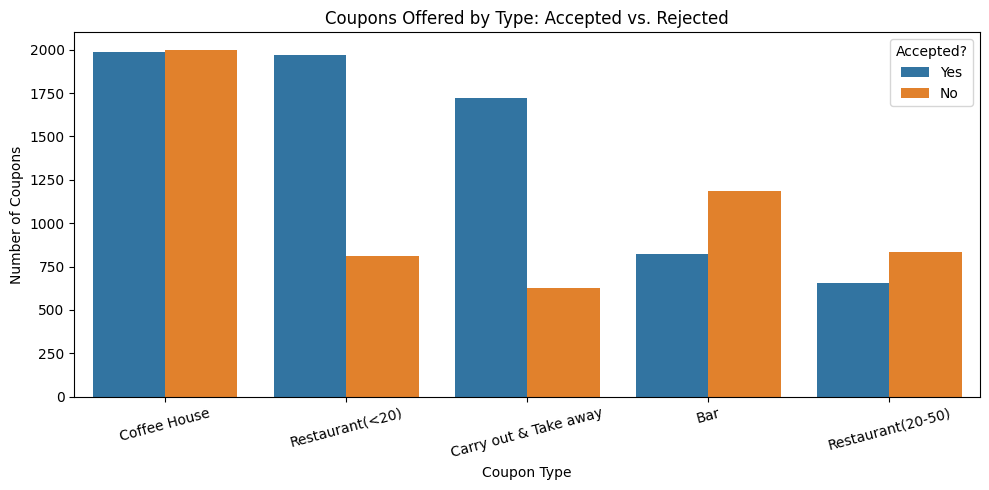

In [ ]:
coupon_order = data['coupon'].value_counts().index   # most common type first

plt.figure(figsize=(10, 5))
sns.countplot(data=data, x='coupon', hue='accepted',
              order=coupon_order, hue_order=['Yes', 'No'])
plt.title('Coupons Offered by Type: Accepted vs. Rejected')
plt.xlabel('Coupon Type')
plt.ylabel('Number of Coupons')
plt.xticks(rotation=15)          # tilt labels so they don't overlap
plt.legend(title='Accepted?')
plt.tight_layout()
plt.show()

6. Use a histogram to visualize the temperature column.

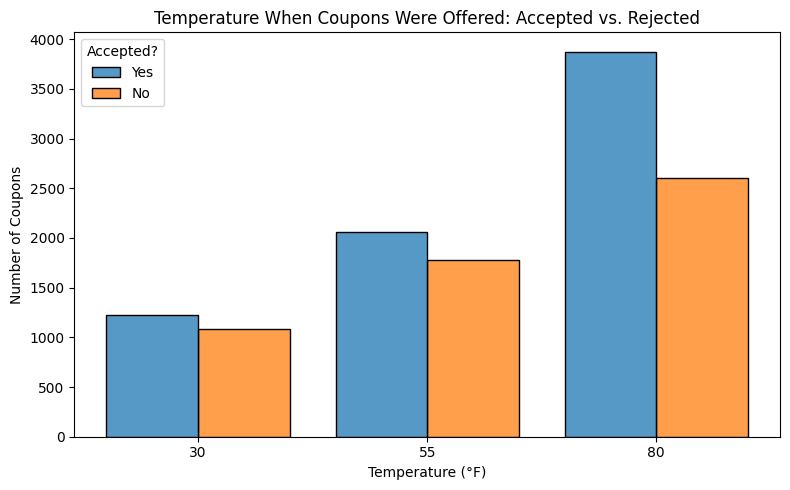

In [ ]:
# Temperature only has three values (30, 55, 80), so give each its own bin
plt.figure(figsize=(8, 5))
sns.histplot(data=data, x='temperature', hue='accepted', hue_order=['Yes', 'No'],
             bins=[17.5, 42.5, 67.5, 92.5], multiple='dodge', shrink=0.8)
plt.title('Temperature When Coupons Were Offered: Accepted vs. Rejected')
plt.xlabel('Temperature (°F)')
plt.ylabel('Number of Coupons')
plt.xticks([30, 55, 80])
sns.move_legend(plt.gca(), 'upper left', title='Accepted?')
plt.tight_layout()
plt.show()

##Observations                                         
About 56.8% of all coupons were accepted. Carry out & Take away (73%) and inexpensive restaurant (71%) coupons are the most popular, while Bar (41%) and expensive restaurant (44%) coupons are accepted less than half the time. Coupons offered on warm days (80°F) were accepted slightly more often (60%) than on cooler days (about 53%).

**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


In [ ]:
# Keep only the rows where the coupon was for a bar
bar_coupons = data[data['coupon'] == 'Bar'].copy()
print('Number of bar coupons:', len(bar_coupons))

Number of bar coupons: 2010


2. What proportion of bar coupons were accepted?


In [ ]:
print(f"Bar coupon acceptance rate: {bar_coupons['Y'].mean():.1%}")

Bar coupon acceptance rate: 41.0%


3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


In [ ]:
# Text codes that belong to each group (the data stores these as text, not numbers)
bar_3_or_fewer     = ['never', 'less1', '1~3']
bar_more_than_once = ['1~3', '4~8', 'gt8']
over_25            = ['26', '31', '36', '41', '46', '50plus']
under_30           = ['below21', '21', '26']
cheap_rest_4_plus  = ['4~8', 'gt8']
income_under_50k   = ['Less than $12500', '$12500 - $24999',
                      '$25000 - $37499', '$37500 - $49999']

def compare_rates(df, condition, group_label, other_label='Everyone else'):
    """Print the acceptance rate for rows matching the condition vs. all other rows."""
    print(f"{group_label}: {df[condition]['Y'].mean():.1%}  (n = {condition.sum()})")
    print(f"{other_label}: {df[~condition]['Y'].mean():.1%}  (n = {(~condition).sum()})")

# Drivers who go to a bar 3 or fewer times a month vs. more often
goes_3_or_fewer = bar_coupons['Bar'].isin(bar_3_or_fewer)
compare_rates(bar_coupons, goes_3_or_fewer, '3 or fewer times a month', 'More than 3 times a month')

3 or fewer times a month: 37.1%  (n = 1811)
More than 3 times a month: 76.9%  (n = 199)


4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


In [ ]:
# & means BOTH conditions must be true
frequent_over_25 = (bar_coupons['Bar'].isin(bar_more_than_once) &
                    bar_coupons['age'].isin(over_25))
compare_rates(bar_coupons, frequent_over_25, 'Bar more than once a month AND over 25')

Bar more than once a month AND over 25: 69.5%  (n = 420)
Everyone else: 33.5%  (n = 1590)


5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


In [ ]:
# != means "not equal to"
frequent_no_kids_not_farming = (bar_coupons['Bar'].isin(bar_more_than_once) &
                                (bar_coupons['passanger'] != 'Kid(s)') &
                                (bar_coupons['occupation'] != 'Farming Fishing & Forestry'))
compare_rates(bar_coupons, frequent_no_kids_not_farming,
              'Bar more than once a month, no kids, not farming/fishing/forestry')

Bar more than once a month, no kids, not farming/fishing/forestry: 71.3%  (n = 551)
Everyone else: 29.5%  (n = 1459)


6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



In [ ]:
# Group 1: bar more than once a month, no kid passengers, not widowed
group_1 = (bar_coupons['Bar'].isin(bar_more_than_once) &
           (bar_coupons['passanger'] != 'Kid(s)') &
           (bar_coupons['maritalStatus'] != 'Widowed'))

# Group 2: bar more than once a month and under 30
group_2 = (bar_coupons['Bar'].isin(bar_more_than_once) &
           bar_coupons['age'].isin(under_30))

# Group 3: cheap restaurants more than 4 times a month and income under $50K
group_3 = (bar_coupons['RestaurantLessThan20'].isin(cheap_rest_4_plus) &
           bar_coupons['income'].isin(income_under_50k))

# | means OR: a driver counts if they fit ANY of the three groups
compare_rates(bar_coupons, group_1 | group_2 | group_3, 'Fits at least one of the three groups')
print()
compare_rates(bar_coupons, group_1, 'Group 1')
compare_rates(bar_coupons, group_2, 'Group 2')
compare_rates(bar_coupons, group_3, 'Group 3')

Fits at least one of the three groups: 58.9%  (n = 776)
Everyone else: 29.7%  (n = 1234)

Group 1: 71.3%  (n = 551)
Everyone else: 29.5%  (n = 1459)
Group 2: 72.2%  (n = 345)
Everyone else: 34.5%  (n = 1665)
Group 3: 45.3%  (n = 344)
Everyone else: 40.1%  (n = 1666)


7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

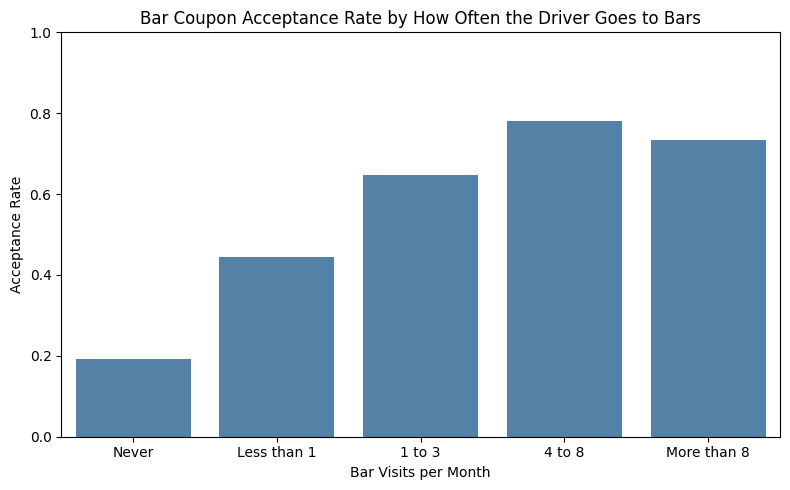

In [ ]:
# Acceptance rate for each bar-visit frequency (the average of Y = acceptance rate)
bar_order = ['never', 'less1', '1~3', '4~8', 'gt8']

plt.figure(figsize=(8, 5))
sns.barplot(data=bar_coupons, x='Bar', y='Y', order=bar_order, errorbar=None, color='steelblue')
plt.title('Bar Coupon Acceptance Rate by How Often the Driver Goes to Bars')
plt.xlabel('Bar Visits per Month')
plt.ylabel('Acceptance Rate')
plt.xticks(range(5), ['Never', 'Less than 1', '1 to 3', '4 to 8', 'More than 8'])
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

##Hypothesis                                           
The strongest predictor of accepting a bar coupon is already being a regular bar-goer. Drivers who visit bars more than 3 times a month accepted 77% of bar coupons, compared with 37% for less frequent visitors, and only 19% of people who never go to bars accepted. Being a frequent bar-goer combined with being younger (under 30), being over 25, or not having kids in the car all pushed acceptance to roughly 70%. In contrast, cheap-restaurant habits and lower income barely mattered (45% vs. 40%). Bar coupons should be targeted at existing bar-goers who are driving without children.

### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

##Problem Statement

What kinds of drivers and driving situations lead to a Coffee House coupon being accepted? Coffee House coupons are the most common coupon in the dataset, yet only about half are accepted. Knowing who accepts them would let the coupon system send fewer wasted offers.

In [ ]:
# Keep only Coffee House coupons
coffee_coupons = data[data['coupon'] == 'Coffee House'].copy()
coffee_rate = coffee_coupons['Y'].mean()

print('Number of coffee house coupons:', len(coffee_coupons))
print(f'Coffee house acceptance rate: {coffee_rate:.1%}')

Number of coffee house coupons: 3989
Coffee house acceptance rate: 49.9%


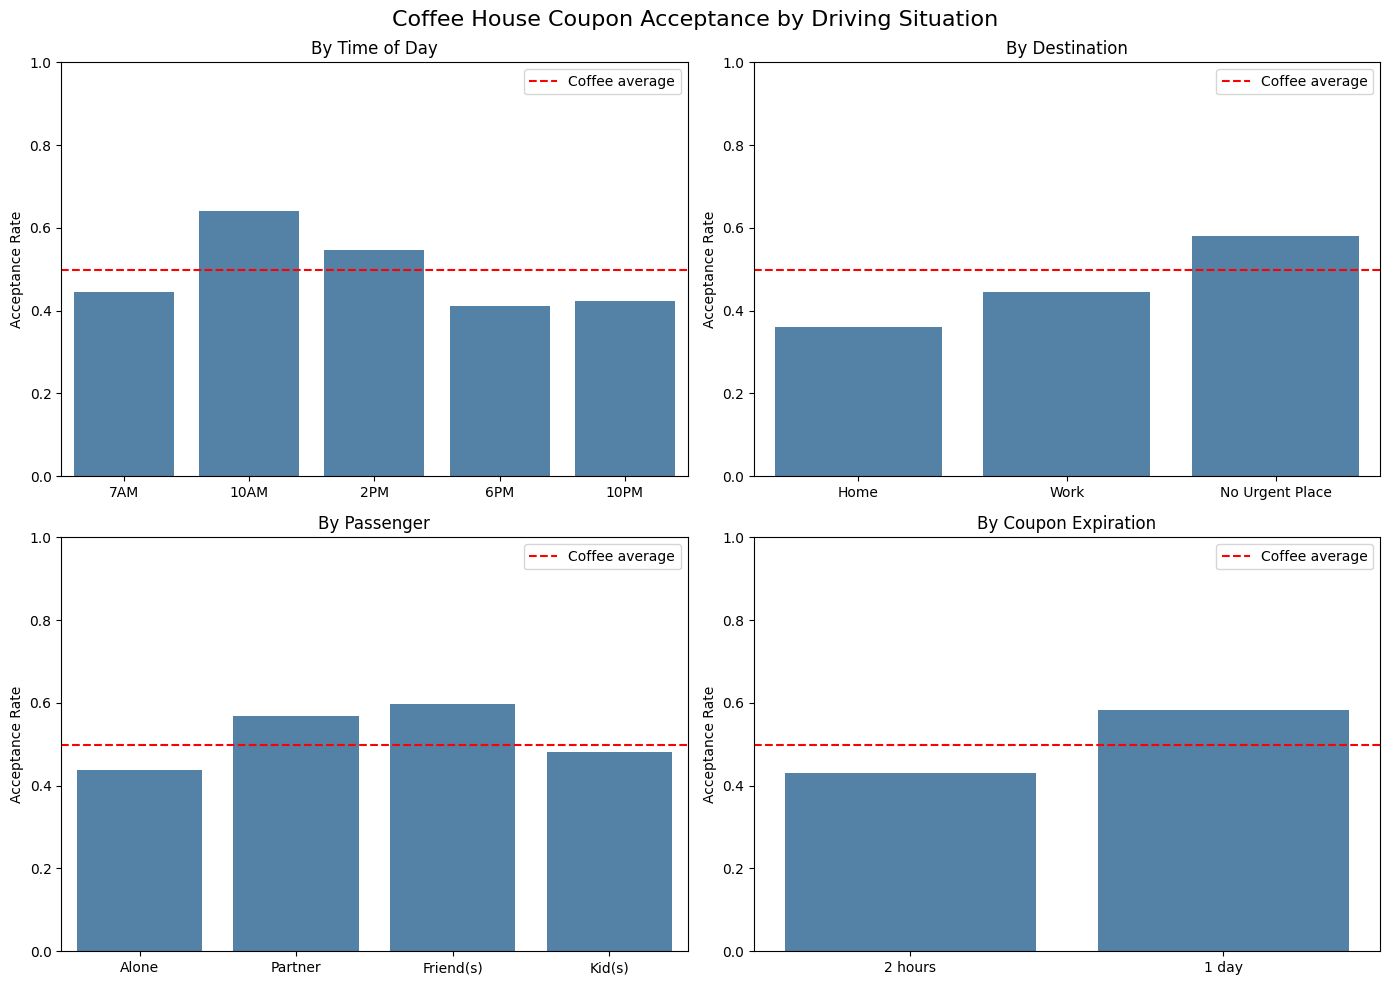

In [ ]:
def plot_acceptance(ax, column, order, title, tick_labels=None):
    """Bar chart of coffee coupon acceptance rate for each value of a column."""
    sns.barplot(data=coffee_coupons, x=column, y='Y', order=order,
                errorbar=None, color='steelblue', ax=ax)
    ax.axhline(coffee_rate, color='red', linestyle='--', label='Coffee average')
    ax.set_title(title)
    ax.set_xlabel('')
    ax.set_ylabel('Acceptance Rate')
    ax.set_ylim(0, 1)
    if tick_labels:
        ax.set_xticks(range(len(order)))
        ax.set_xticklabels(tick_labels)
    ax.legend(loc='upper right')

# 2 rows x 2 columns of plots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
plot_acceptance(axes[0, 0], 'time', ['7AM', '10AM', '2PM', '6PM', '10PM'], 'By Time of Day')
plot_acceptance(axes[0, 1], 'destination', ['Home', 'Work', 'No Urgent Place'], 'By Destination')
plot_acceptance(axes[1, 0], 'passanger', ['Alone', 'Partner', 'Friend(s)', 'Kid(s)'], 'By Passenger')
plot_acceptance(axes[1, 1], 'expiration', ['2h', '1d'], 'By Coupon Expiration',
                ['2 hours', '1 day'])
fig.suptitle('Coffee House Coupon Acceptance by Driving Situation', fontsize=16)
plt.tight_layout()
plt.show()

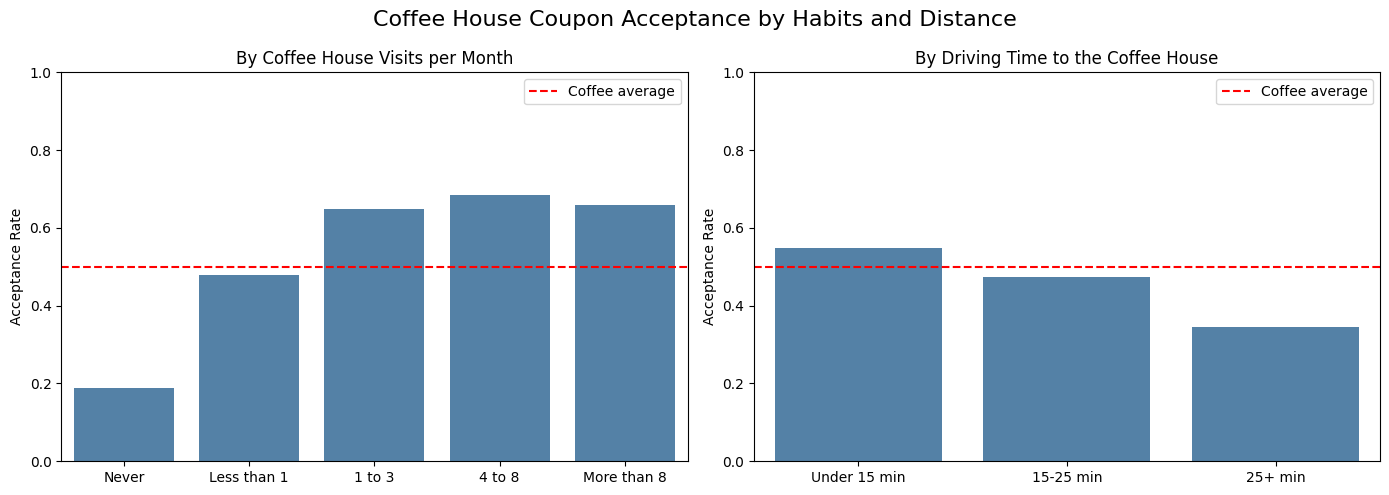

In [ ]:
# Combine the two distance columns into one readable category
coffee_coupons['drive_time'] = np.select(
    [coffee_coupons['toCoupon_GEQ25min'] == 1, coffee_coupons['toCoupon_GEQ15min'] == 1],
    ['25+ min', '15-25 min'],
    default='Under 15 min')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_acceptance(axes[0], 'CoffeeHouse', ['never', 'less1', '1~3', '4~8', 'gt8'],
                'By Coffee House Visits per Month',
                ['Never', 'Less than 1', '1 to 3', '4 to 8', 'More than 8'])
plot_acceptance(axes[1], 'drive_time', ['Under 15 min', '15-25 min', '25+ min'],
                'By Driving Time to the Coffee House')
fig.suptitle('Coffee House Coupon Acceptance by Habits and Distance', fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
coffee_regular = ['1~3', '4~8', 'gt8']   # visits a coffee house at least once a month
regular = coffee_coupons['CoffeeHouse'].isin(coffee_regular)

compare_rates(coffee_coupons, regular, 'Regular coffee drinkers')
print()

regular_no_rush = regular & (coffee_coupons['destination'] == 'No Urgent Place')
compare_rates(coffee_coupons, regular_no_rush, 'Regulars with no urgent destination')
print()

best_target = regular_no_rush & coffee_coupons['time'].isin(['10AM', '2PM'])
compare_rates(coffee_coupons, best_target, 'Regulars, no urgent destination, 10AM or 2PM')

Regular coffee drinkers: 66.0%  (n = 1918)
Everyone else: 34.9%  (n = 2071)

Regulars with no urgent destination: 73.8%  (n = 1036)
Everyone else: 41.4%  (n = 2953)

Regulars, no urgent destination, 10AM or 2PM: 77.4%  (n = 810)
Everyone else: 42.8%  (n = 3179)


In [ ]:
from scipy.stats import chi2_contingency

# Test each factor: is it related to whether the coupon was accepted?
factors = ['CoffeeHouse', 'time', 'destination', 'passanger', 'expiration',
           'drive_time', 'age', 'income', 'gender', 'has_children']
results = []
for factor in factors:
    table = pd.crosstab(coffee_coupons[factor], coffee_coupons['Y'])
    chi2, p_value, dof, expected = chi2_contingency(table)
    results.append({'factor': factor, 'chi_square': round(chi2, 1), 'p_value': p_value})

results_df = pd.DataFrame(results).sort_values('chi_square', ascending=False)
results_df['significant (p < 0.05)'] = results_df['p_value'] < 0.05
results_df['p_value'] = results_df['p_value'].map('{:.4f}'.format)
print(results_df.to_string(index=False))

      factor  chi_square p_value  significant (p < 0.05)
 CoffeeHouse       559.8  0.0000                    True
 destination       136.5  0.0000                    True
        time       129.9  0.0000                    True
  expiration        89.6  0.0000                    True
   passanger        86.6  0.0000                    True
      income        60.1  0.0000                    True
  drive_time        52.0  0.0000                    True
         age        44.1  0.0000                    True
has_children         1.1  0.2874                   False
      gender         0.8  0.3862                   False


## Findings

**Overall:** 56.8% of all coupons were accepted. Carry out (73%) and cheap restaurant (71%) coupons performed best. Bar (41%) and expensive restaurant (44%) coupons performed worst.

**Bar coupons:** Habit matters most. Drivers who visit bars more than 3 times a month accepted 77% of bar coupons, compared with 37% for everyone else. Only 19% of people who never go to bars accepted.

### Coffee House Coupons (49.9% accepted)

- **Existing habit is the strongest predictor.** Regular coffee house visitors (1+ times a month) accepted 66% of coupons. People who never go accepted only 19%.
- **The situation matters.** Acceptance was highest at 10AM (64%), when there was no urgent destination (58%), and with friends in the car (60%). It was lowest on the way home (36%) and in the evening (41%).
- **Convenience matters.** A 1-day expiration beat a 2-hour one (58% vs. 43%), and acceptance fell to 35% when the coffee house was 25+ minutes away.
- **The best target group** was regular coffee drinkers with no urgent destination at 10AM or 2PM. They accepted **77%** of coupons.
- **Gender and having children made no difference** (chi-square test, p > 0.05).

### Recommendations

1. **Send coffee coupons to existing coffee drinkers** and mostly stop sending them to people who never visit coffee houses.
2. **Time them for mid-morning and early afternoon**, when the driver isn't heading home or to work.
3. **Use 1-day expirations** instead of 2-hour ones.
4. **Only offer coffee houses within about 15 minutes** of the driver.

### Next Steps

- Build a classification model (such as logistic regression or a decision tree) to predict whether a driver will accept a coupon.
- Test these targeting rules in a real A/B experiment, since this data comes from a survey of imagined situations rather than real coupon use.
- Repeat this analysis for the other coupon types.